# Joint Kelly sizing for ladders

**Question:** when we bet several lines on the same player (O1.5 / O2.5 / O3.5), is sizing each leg with its own Kelly stake right, and what would sizing the ladder *jointly* have done to our history?

**Roadmap**
1. Single-bet Kelly: where `kellyCrit` comes from
2. Why ladder legs are not independent bets
3. Joint Kelly: the objective, the first-order conditions, and why the top rung gets dropped
4. Only cell probabilities matter: backing the model's probability out of our historical stakes
5. Historical replay on Pikkit (2024-25, 2025-26): actual vs joint sizing
6. Right-tail calibration by rung
7. Sensitivity to the bankroll assumption

Conventions: decimal odds $d$, net odds $b = d-1$, win probability $p$, bankroll $B$, Kelly fraction $\lambda = 1/8$.

In [1]:
import re, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

DB_PATH = '../nba/data/database/nba.db'
PIKKIT_PATH = '../nba/data/pikkit/transactions.csv'
LAMBDA = 1 / 8   # kellyVal = .125 in betting/funcs.py

# Static bankroll per season. 2024-25: notebook note (Mar 2025) "eighth kelly and 500 budget".
# 2025-26: budget = 1000 in funcs.py at the 3/31/26 season snapshot. 2026-27: app sidebar default.
# CONFIRM THESE - section 7 shows how sensitive the results are to them.
BANKROLL = {'2024-25': 500, '2025-26': 1000, '2026-27': 1000}

con = sqlite3.connect('file:{}?mode=ro'.format(DB_PATH), uri=True)

## 1. Single-bet Kelly

Bet a fraction $f$ of the bankroll. Wealth multiplier after the bet:

$$W = \begin{cases} 1 + f b & \text{with prob } p \\ 1 - f & \text{with prob } 1-p \end{cases}$$

Kelly maximizes expected **log** wealth (equivalently, the long-run growth rate, because log wealth after $n$ bets is a sum and the LLN applies to the average):

$$g(f) = p\log(1+fb) + (1-p)\log(1-f)$$

Set the derivative to zero:

$$g'(f) = \frac{pb}{1+fb} - \frac{1-p}{1-f} = 0 \;\Rightarrow\; f^* = p - \frac{1-p}{b} = \frac{pd-1}{d-1}$$

That is exactly `kv = prob - (1-prob)/b` in `kellyCrit`, and the stake is $\lambda B f^*$.

Two facts worth seeing on a chart:
- $g$ is concave, so there is one maximum.
- Near the optimum $g(f) \approx f\cdot\text{edge} - \tfrac12 f^2\sigma^2$, a parabola: growth at $2f^*$ is roughly **zero**, and beyond $2f^*$ it is negative. Overbetting is much worse than underbetting.

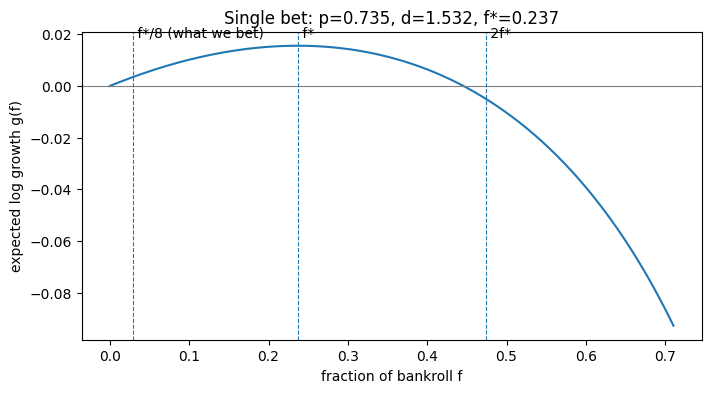

growth at f*: 0.01558   at 2f*: -0.00491   at f*/8: 0.00352


In [2]:
def dec(american):
    return 1 + american / 100 if american > 0 else 1 + 100 / abs(american)

def kelly_single(p, d):
    return (p * d - 1) / (d - 1)

# Example: Toumani Camara O1.5 at -188 on 10/21, model p = .735
p, d = 0.735, dec(-188)
fstar = kelly_single(p, d)
f = np.linspace(0, min(0.99, 3 * fstar), 300)
g = p * np.log(1 + f * (d - 1)) + (1 - p) * np.log(1 - f)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(f, g)
ax.axhline(0, color='grey', lw=.8)
for x, lab in [(fstar, 'f*'), (2 * fstar, '2f*'), (LAMBDA * fstar, 'f*/8 (what we bet)')]:
    ax.axvline(x, ls='--', lw=.8)
    ax.text(x, ax.get_ylim()[1] * .9, ' ' + lab)
ax.set_xlabel('fraction of bankroll f'); ax.set_ylabel('expected log growth g(f)')
ax.set_title('Single bet: p={:.3f}, d={:.3f}, f*={:.3f}'.format(p, d, fstar))
plt.show()
print('growth at f*: {:.5f}   at 2f*: {:.5f}   at f*/8: {:.5f}'.format(
    np.interp(fstar, f, g), np.interp(2 * fstar, f, g), np.interp(LAMBDA * fstar, f, g)))

## 2. Why ladder legs are not independent

Single-bet Kelly for each leg quietly assumes **that leg is the only bet**. A ladder breaks that, because every leg pays off as a function of the same random variable $X$ (threes made).

Below is Camara on 10/21 using the model's full PMF. Rows are outcomes $X=k$, columns are legs, entries are the net return $R_{ki}$ per $1 staked ($d_i-1$ if the leg wins, $-1$ if it loses).

Two things to notice:
- **Losses stack.** In every state $X \le 1$, all three legs lose together, so wealth is $1 - \sum_i f_i$.
- **Wins stack.** Whenever O3.5 wins, O1.5 and O2.5 already won. The top rung only pays in states where we are already up.

Each single-leg Kelly was computed as if neither were true.

In [3]:
D = '2026-10-21'
PLAYER = 'Toumani Camara'
legs = pd.read_sql(
    "select b.player_id, p.name, b.over_under, b.number, b.final_line, b.bet_amount "
    "from bets b join players p using(player_id) where b.date = ? and p.name = ? order by b.number",
    con, params=(D, PLAYER))
pid = legs.player_id.iloc[0]
pmf = pd.read_sql("select number as k, model_prob as p from predictions where date = ? and player_id = ? order by number",
                  con, params=(D, int(pid)))
k = pmf.k.values
p_k = pmf.p.values / pmf.p.sum()

legs['d'] = legs.final_line.apply(dec)
win = np.column_stack([(k > n) if s == 'Over' else (k < n) for s, n in zip(legs.over_under, legs.number)])
R = np.where(win, legs.d.values - 1, -1.0)
legs['model_p'] = [p_k[win[:, i]].sum() for i in range(len(legs))]
legs['f_indep'] = kelly_single(legs.model_p, legs.d)

leg_names = (legs.over_under.str[0] + legs.number.astype(str)).tolist()
payoff = pd.DataFrame(R, columns=leg_names)
payoff.insert(0, 'P(X=k)', p_k.round(3))
payoff.insert(0, 'X', k)
payoff['W at sum of indep f*'] = 1 + R @ legs.f_indep.values
print(legs[['name', 'over_under', 'number', 'final_line', 'model_p', 'f_indep', 'bet_amount']].round(4).to_string(index=False))
print()
print(payoff[payoff.X <= 6].round(3).to_string(index=False))
print('\nSum of independent full-Kelly fractions: {:.3f} -> lost together with prob P(X<=1) = {:.3f}'.format(
    legs.f_indep.sum(), p_k[k <= 1].sum()))

          name over_under  number  final_line  model_p  f_indep  bet_amount
Toumani Camara       Over     1.5      -188.0   0.7346   0.2356       29.50
Toumani Camara       Over     2.5       172.0   0.4557   0.1393       17.50
Toumani Camara       Over     3.5       430.0   0.2288   0.0495        6.25

  X  P(X=k)   O1.5  O2.5  O3.5  W at sum of indep f*
0.0   0.057 -1.000 -1.00  -1.0                 0.576
1.0   0.209 -1.000 -1.00  -1.0                 0.576
2.0   0.279  0.532 -1.00  -1.0                 0.937
3.0   0.227  0.532  1.72  -1.0                 1.315
4.0   0.139  0.532  1.72   4.3                 1.578
5.0   0.059  0.532  1.72   4.3                 1.578
6.0   0.019  0.532  1.72   4.3                 1.578

Sum of independent full-Kelly fractions: 0.424 -> lost together with prob P(X<=1) = 0.265


## 3. Joint Kelly

Choose all leg fractions together to maximize expected log wealth over the **joint** outcome distribution:

$$\max_{f \ge 0}\; g(f) = \sum_k p_k \log W_k, \qquad W_k = 1 + \sum_i f_i R_{ki}$$

**It has exactly one answer.** $\log$ of an affine function is concave, and a sum of concave functions is concave, so any local maximum is the global one. A bounded quasi-Newton solver (L-BFGS-B) finds it, given the gradient below.

**First-order (KKT) conditions.** The gradient is

$$\frac{\partial g}{\partial f_i} = \sum_k p_k \frac{R_{ki}}{W_k}$$

and at the optimum, for each leg: $\partial g/\partial f_i = 0$ if $f_i > 0$, and $\partial g/\partial f_i \le 0$ if $f_i = 0$.

**This is the intuition to hold onto.** $1/W_k$ is the marginal value of a dollar in state $k$. A leg's payoff is weighted by how much we *need* money in the states where it pays.
- The top rung only pays in states where the lower rungs already paid, so $W_k$ is large and its payoff is discounted. If the discounted payoff doesn't cover its losses, the optimizer sets it to zero. That's why the top rung is the one that can go to **zero**: the cause is the overlap with the lower rungs, not the model's tail.
- The overlap runs in both directions, though. The bottom rung also pays in every state where the upper rungs pay, and it carries the biggest stake. So in **dollars**, the bottom rung usually gives up the most (section 5b).
- Single-leg Kelly is the special case with $W_k$ evaluated as if no other bets existed.

**Fractional Kelly** for a portfolio is $\lambda f^{\text{joint}}$: hold a fraction $\lambda$ of the Kelly portfolio. The stake is $\lambda B f_i^{\text{joint}}$.

In [4]:
def joint_kelly(p, R):
    """Full-Kelly fractions for legs whose net returns R (cells x legs) depend on one outcome with cell probabilities p."""
    n = R.shape[1]

    def neg_growth(f):
        W = 1 + R @ f
        if (W <= 0).any():
            return 1e6
        return -(p @ np.log(W))

    def neg_grad(f):
        W = 1 + R @ f
        return -(R.T @ (p / W))

    res = minimize(neg_growth, np.full(n, 0.01), jac=neg_grad, bounds=[(0, 0.999)] * n, method='L-BFGS-B')
    return res.x

def growth_and_grad(p, R, f):
    W = 1 + R @ f
    return p @ np.log(W), R.T @ (p / W)

f_joint = joint_kelly(p_k, R)
g_ind, grad_ind = growth_and_grad(p_k, R, legs.f_indep.values)
g_jnt, grad_jnt = growth_and_grad(p_k, R, f_joint)

out = legs[['over_under', 'number', 'final_line', 'model_p', 'f_indep']].copy()
out['f_joint'] = f_joint
out['grad @ indep'] = grad_ind
out['grad @ joint'] = grad_jnt
out['stake_actual'] = legs.bet_amount
out['stake_joint'] = LAMBDA * BANKROLL['2026-27'] * f_joint
print(out.round(4).to_string(index=False))
print('\nExpected log growth (full Kelly): sum-of-independent = {:.4f}   joint = {:.4f}'.format(g_ind, g_jnt))
print('Gradient at the independent sizes is negative for every leg -> every leg is overbet given the others.')
print('At the joint optimum: ~0 for legs kept, negative for legs dropped (KKT).')

over_under  number  final_line  model_p  f_indep  f_joint  grad @ indep  grad @ joint  stake_actual  stake_joint
      Over     1.5      -188.0   0.7346   0.2356   0.1395       -0.1338       -0.0000         29.50      17.4322
      Over     2.5       172.0   0.4557   0.1393   0.0962       -0.2127       -0.0000         17.50      12.0203
      Over     3.5       430.0   0.2288   0.0495   0.0000       -0.3077       -0.0217          6.25       0.0000

Expected log growth (full Kelly): sum-of-independent = 0.0017   joint = 0.0204
Gradient at the independent sizes is negative for every leg -> every leg is overbet given the others.
At the joint optimum: ~0 for legs kept, negative for legs dropped (KKT).


single-leg Kelly 0.23562  vs joint solver on that leg alone 0.23560


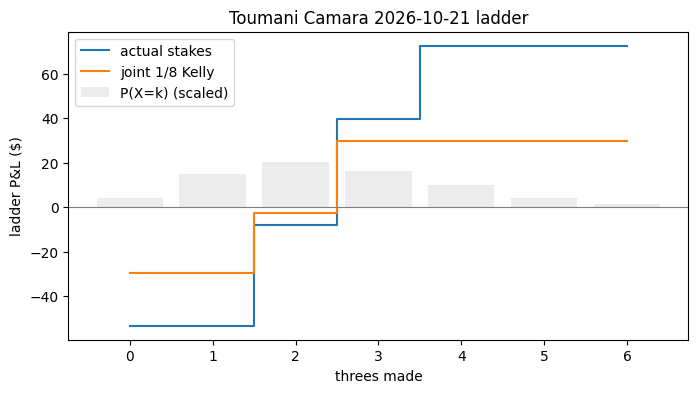

In [5]:
# Sanity check: with one leg, joint Kelly must equal single-bet Kelly
i = 0
print('single-leg Kelly {:.5f}  vs joint solver on that leg alone {:.5f}'.format(
    legs.f_indep.iloc[i], joint_kelly(p_k, R[:, [i]])[0]))

# Payoff profile by outcome: actual stakes vs joint stakes
pl_actual = R @ legs.bet_amount.values
pl_joint = R @ out.stake_joint.values
kk = k <= 6
fig, ax = plt.subplots(figsize=(8, 4))
ax.step(k[kk], pl_actual[kk], where='mid', label='actual stakes')
ax.step(k[kk], pl_joint[kk], where='mid', label='joint 1/8 Kelly')
ax.bar(k[kk], p_k[kk] * max(abs(pl_actual).max(), 1), alpha=.15, color='grey', label='P(X=k) (scaled)')
ax.axhline(0, color='grey', lw=.8)
ax.set_xlabel('threes made'); ax.set_ylabel('ladder P&L ($)'); ax.set_title('{} {} ladder'.format(PLAYER, D)); ax.legend()
plt.show()

## 4. What we need from history: cell probabilities only

Within a ladder, every leg's payoff is constant between consecutive lines. Lines $t_1 < \dots < t_m$ cut the outcomes into $m+1$ **cells** ($X<t_1$, $t_1<X<t_2$, …, $X>t_m$). The joint problem only needs the probability of each cell, and those come from the survival function at the lines, $S(t) = P(X > t)$:

$$P(\text{cell}_0) = 1-S(t_1),\quad P(\text{cell}_j) = S(t_j)-S(t_{j+1}),\quad P(\text{cell}_m) = S(t_m)$$

An over at $t$ gives $S(t)=p$, and an under at $t$ gives $S(t)=1-p$. $S$ has to be non-increasing; a violation means the backed-out probabilities are inconsistent, and those ladders get flagged.

**We didn't store historical PMFs, but we did store the stakes.** Each stake was $s = \lambda B f^*$ with $f^* = (pd-1)/(d-1)$, so

$$p = \frac{\dfrac{s}{\lambda B}(d-1) + 1}{d}$$

Every historical stake therefore encodes the model's probability at bet time. Where this breaks:
- **Limited fills** (theScore, bet365) make the stake too small, so $p$ is biased toward the book's price.
- **Manual overrides and rounding.** $s > \lambda B$ implies $p>1$; those ladders are flagged and excluded.
- **The bankroll assumption** ($B$). Section 7 tests it.

First, validate the back-out on this season, where we have both the stakes and the true PMF.

count    82.0000
mean      0.0017
std       0.0194
min      -0.0212
25%      -0.0004
50%      -0.0001
75%       0.0002
max       0.1708
Name: diff, dtype: float64

Legs where the stake does not match Kelly (|diff| > .01):
player_id       date over_under  number  final_line  bet_amount  model_p     d  backed_p   diff
  1628384 2026-10-20       Over     3.5       420.0        5.00    0.209 5.200     0.225  0.016
  1629014 2026-10-20       Over     1.5      -122.0       40.00    0.707 1.820     0.694 -0.013
  1629027 2026-10-21      Under     2.5      -150.0      100.00    0.749 1.667     0.920  0.171
  1629636 2026-10-21      Under     3.5      -165.0       16.50    0.694 1.606     0.672 -0.021
  1630180 2026-10-21       Over     2.5       415.0       22.00    0.322 5.150     0.336  0.014
  1630202 2026-10-20      Under     2.5      -104.0       30.00    0.639 1.962     0.627 -0.011
  1642258 2026-10-21      Under     0.5       168.0       17.25    0.446 2.680     0.460  0.014
  1642846 

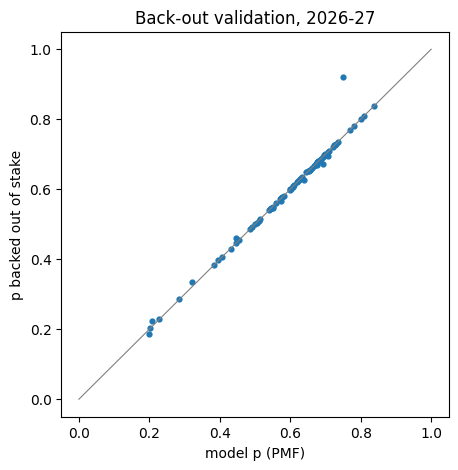

In [6]:
def back_out_p(stake, d, bankroll):
    return ((stake / (LAMBDA * bankroll)) * (d - 1) + 1) / d

cur = pd.read_sql("select b.player_id, b.date, b.over_under, b.number, b.final_line, b.bet_amount "
                  "from bets b where b.date >= '2026-10-01'", con)
pr = pd.read_sql("select player_id, date, number as k, model_prob as p from predictions where date >= '2026-10-01'", con)
pr['player_id'] = pr.player_id.astype(str)
pr['p'] = pr.p / pr.groupby(['player_id', 'date']).p.transform('sum')
cur = cur.merge(pr, on=['player_id', 'date'])
cur['win_k'] = np.where(cur.over_under == 'Over', cur.k > cur.number, cur.k < cur.number)
cur = (cur.assign(pw=cur.p * cur.win_k)
          .groupby(['player_id', 'date', 'over_under', 'number', 'final_line', 'bet_amount'], as_index=False).pw.sum()
          .rename(columns={'pw': 'model_p'}))
cur['d'] = cur.final_line.apply(dec)
cur['backed_p'] = back_out_p(cur.bet_amount, cur.d, BANKROLL['2026-27'])
cur['diff'] = cur.backed_p - cur.model_p
print(cur['diff'].describe().round(4))
print('\nLegs where the stake does not match Kelly (|diff| > .01):')
print(cur[cur['diff'].abs() > .01].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(cur.model_p, cur.backed_p, s=12)
ax.plot([0, 1], [0, 1], color='grey', lw=.8)
ax.set_xlabel('model p (PMF)'); ax.set_ylabel('p backed out of stake'); ax.set_title('Back-out validation, 2026-27')
plt.show()

## 5. Historical replay: actual vs joint sizing

Steps:
1. Parse the Pikkit export (straight NBA threes props, settled win/loss), date bets in ET, and assign seasons.
2. Merge **split legs** (same player, date, side, line across books) into one leg with the summed stake and payout-equivalent odds $\bar d = \sum s d / \sum s$.
3. Back out $p$ for each leg using that season's bankroll.
4. A **ladder** is a player-date with more than one distinct line. Build cells, check monotonicity, solve joint Kelly, and set stake $= \lambda B f^{\text{joint}}$.
5. Singles are untouched; they appear identically in both arms of the daily series.

Realized P&L for both arms uses the same odds and the same win/loss outcomes. Only the stakes differ.

In [7]:
PATTERNS = [
    (r'^(?P<side>Over|Under) (?P<num>\d+\.5) (?P<name>.+?) Three Pointers Made', None),               # DK O/U
    (r'^(?P<k>\d+)\+ (?P<name>.+?) Three Pointers Made', 'plus'),                                     # DK alt
    (r'^(?P<name>.+?) (?P<k>\d+)\+ Made Threes', 'plus'),                                             # FD alt
    (r'^(?P<name>.+?) (?P<side>Over|Under) (?P<num>\d+\.5) .*(?:Made Threes|Alt Threes)', None),      # FD O/U
    (r'^(?P<name>.+?) - (?P<side>Over|Under) (?P<num>\d+\.5) Threes Made', None),                     # 365 O/U
    (r'^(?P<name>[^:]+): (?P<k>\d+)\+ Threes Made', 'plus'),                                          # 365 alt
    (r'^(?P<side>Over|Under) (?P<num>\d+\.5) (?P<name>.+?) (?:\(\w+\) ?)?: ?Three', None),            # MGM O/U
    (r'^Yes (?P<name>.+?) to make (?P<k>\d+)\+ three', 'plus'),                                       # MGM yes
    (r'^(?P<side>Over|Under) (?P<num>\d+\.5) (?P<name>.+?) Total 3-Pointers', None),                  # theScore O/U
    (r'^(?P<k>\d+)\+ (?P<name>.+?) Total 3-Pointers', 'plus'),                                        # theScore alt
]

def parse_market(s):
    for pat, kind in PATTERNS:
        m = re.search(pat, s)
        if m:
            g = m.groupdict()
            if kind == 'plus':
                return g['name'].strip(), 'Over', int(g['k']) - 0.5
            return g['name'].strip(), g['side'], float(g['num'])
    return None

pk = pd.read_csv(PIKKIT_PATH)
pk = pk[(pk.type == 'straight') & (pk.leagues == 'NBA')]
pk = pk[pk.bet_info.str.contains(r'Three|3-Pointers|three-pointers', case=False, na=False)]
pk = pk[~pk.bet_info.str.contains(r'Most Three|Race to|combine|First|1st|Q1| v ', na=False)]
parsed = pk.bet_info.apply(parse_market)
print('parsed {:.1%} of {} threes rows'.format(parsed.notna().mean(), len(pk)))
pk = pk[parsed.notna()].copy()
pk[['name', 'side', 'line']] = pd.DataFrame(parsed[pk.index].tolist(), index=pk.index)
pk = pk[pk.status.isin(['SETTLED_WIN', 'SETTLED_LOSS'])]
et = pd.to_datetime(pk.time_placed_iso).dt.tz_convert('America/New_York')
pk['date'] = et.dt.date
start_year = np.where(et.dt.month >= 8, et.dt.year, et.dt.year - 1)
pk['season'] = ['{}-{}'.format(y, str(y + 1)[2:]) for y in start_year]
pk['won'] = (pk.status == 'SETTLED_WIN').astype(int)
pk = pk[pk.season.isin(BANKROLL.keys())]

# merge split legs
pk['sd'] = pk.amount * pk.odds
legs_h = (pk.groupby(['season', 'date', 'name', 'side', 'line'], as_index=False)
            .agg(stake=('amount', 'sum'), sd=('sd', 'sum'), won=('won', 'max'), pikkit_pl=('profit', 'sum'), n_books=('amount', 'size')))
legs_h['d'] = legs_h.sd / legs_h.stake
legs_h['pl_actual'] = np.where(legs_h.won == 1, legs_h.stake * (legs_h.d - 1), -legs_h.stake)
print('legs after merging splits:', len(legs_h), ' (split legs merged: {})'.format((legs_h.n_books > 1).sum()))
print('recomputed P&L vs Pikkit profit, total diff: ${:.2f}'.format(legs_h.pl_actual.sum() - legs_h.pikkit_pl.sum()))
print(legs_h.groupby('season').agg(legs=('stake', 'size'), stake=('stake', 'sum'), pl=('pl_actual', 'sum')).round(2))

parsed 99.8% of 4427 threes rows
legs after merging splits: 3854  (split legs merged: 47)
recomputed P&L vs Pikkit profit, total diff: $-743.53
         legs     stake       pl
season                          
2024-25   975   8801.95   824.33
2025-26  2879  61748.61  3405.68


In [8]:
def ladder_cells(g):
    """Cell probabilities and net-return matrix for one player-date (rows sorted by line). Returns (p_cells, R, reason)."""
    lines = g.line.values
    if len(np.unique(lines)) != len(lines):
        return None, None, 'both sides at one line'
    S = np.where(g.side == 'Over', g.p, 1 - g.p)
    if (np.diff(S) > 1e-9).any():
        return None, None, 'non-monotone'
    p_cells = np.concatenate([[1 - S[0]], S[:-1] - S[1:], [S[-1]]])
    cell = np.arange(len(lines) + 1)   # cell j = outcomes between line j-1 and line j
    R = np.column_stack([
        np.where(cell > j if s == 'Over' else cell <= j, d - 1, -1.0)
        for j, (s, d) in enumerate(zip(g.side, g.d))])
    return p_cells, R, 'ok'

def replay(legs_in, bank_mult=1.0):
    """Adds backed-out p and joint stakes to every leg. Singles keep their actual stake."""
    L = legs_in.copy()
    L['B'] = L.season.map(BANKROLL) * bank_mult
    L['p'] = back_out_p(L.stake, L.d, L.B)
    L['f_indep'] = kelly_single(L.p, L.d)
    L['n_lines'] = L.groupby(['date', 'name']).line.transform('nunique')
    L['is_ladder'] = L.n_lines > 1
    L['status'] = np.where(L.is_ladder, '', 'single')
    L['stake_joint'] = L.stake
    for key, g in L[L.is_ladder].groupby(['date', 'name']):
        if (g.p >= 1).any():
            L.loc[g.index, 'status'] = 'p>=1'
            continue
        g = g.sort_values('line')
        p_cells, R, reason = ladder_cells(g)
        L.loc[g.index, 'status'] = reason
        if reason == 'ok':
            L.loc[g.index, 'stake_joint'] = LAMBDA * g.B.values * joint_kelly(p_cells, R)
    L['pl_joint'] = np.where(L.won == 1, L.stake_joint * (L.d - 1), -L.stake_joint)
    L['ev_actual'] = L.stake * (L.p * L.d - 1)
    L['ev_joint'] = L.stake_joint * (L.p * L.d - 1)
    return L

H = replay(legs_h)
lad = H[H.is_ladder]
print('ladder legs by status:')
print(lad.groupby(['season', 'status']).size().unstack(fill_value=0))

ladder legs by status:
status   non-monotone    ok  p>=1
season                           
2024-25             0   376     2
2025-26             2  1284     2


### 5a. Season summary (ladders only)

`ev_*` is the model's expected P&L using the backed-out probabilities. `pl_*` is what actually happened. Expect joint sizing to give up some EV and a larger share of the variance.

In [9]:
ok = H[H.status == 'ok']
summ = ok.groupby('season').agg(
    legs=('stake', 'size'),
    stake_actual=('stake', 'sum'), stake_joint=('stake_joint', 'sum'),
    ev_actual=('ev_actual', 'sum'), ev_joint=('ev_joint', 'sum'),
    pl_actual=('pl_actual', 'sum'), pl_joint=('pl_joint', 'sum'))
summ.insert(0, 'ladders', ok.drop_duplicates(['season', 'date', 'name']).groupby('season').size())
summ['roi_actual'] = summ.pl_actual / summ.stake_actual
summ['roi_joint'] = summ.pl_joint / summ.stake_joint
summ['stake_cut'] = 1 - summ.stake_joint / summ.stake_actual
print(summ.round(3).T.to_string())

# Ladder-level dispersion: per-ladder P&L sd, worst ladder
per_lad = ok.groupby(['season', 'date', 'name'])[['pl_actual', 'pl_joint']].sum()
print('\nPer-ladder P&L:')
print(per_lad.groupby('season').agg(['mean', 'std', 'min']).round(2).to_string())

season         2024-25    2025-26
ladders        164.000    571.000
legs           376.000   1284.000
stake_actual  3463.200  25804.300
stake_joint   1802.425  14593.808
ev_actual     1457.831   8094.246
ev_joint       867.786   5088.949
pl_actual      743.716   1505.922
pl_joint       384.424   1214.794
roi_actual       0.215      0.058
roi_joint        0.213      0.083
stake_cut        0.480      0.434

Per-ladder P&L:
        pl_actual                pl_joint              
             mean    std     min     mean    std    min
season                                                 
2024-25      4.53  36.86  -52.50     2.34  20.53  -25.0
2025-26      2.64  58.78 -162.25     2.13  36.06 -100.0


### 5b. By rung (over ladders)

Rung 1 is the lowest line. Where does joint sizing take money from, and did that money make or lose historically?

In [10]:
ov = ok[ok.side == 'Over'].copy()
ov['rung'] = ov.groupby(['date', 'name']).line.rank(method='first').astype(int)
ov['rung'] = ov.rung.clip(upper=3).map({1: '1 (lowest)', 2: '2', 3: '3+'})
ov['dropped'] = ov.stake_joint < 0.005
ov['pl_removed'] = ov.pl_actual - ov.pl_joint
rung = ov.groupby(['season', 'rung']).agg(
    legs=('stake', 'size'), stake_actual=('stake', 'sum'), stake_joint=('stake_joint', 'sum'),
    share_dropped=('dropped', 'mean'), pl_actual=('pl_actual', 'sum'), pl_joint=('pl_joint', 'sum'),
    pl_of_removed_stake=('pl_removed', 'sum'))
rung['stake_cut'] = 1 - rung.stake_joint / rung.stake_actual
print(rung.round(3).to_string())

                    legs  stake_actual  stake_joint  share_dropped  pl_actual  pl_joint  pl_of_removed_stake  stake_cut
season  rung                                                                                                           
2024-25 1 (lowest)   164       1783.84      726.190          0.171     81.886   -22.514              104.399      0.593
        2            164       1354.41      914.924          0.043    463.130   379.844               83.286      0.324
        3+            48        324.95      161.311          0.188    198.700    27.094              171.606      0.504
2025-26 1 (lowest)   389       8947.00     4831.648          0.085   -134.860   -11.770             -123.090      0.460
        2            389       5907.28     3553.854          0.046    246.773    92.620              154.154      0.398
        3+           139       1564.75      643.766          0.086    200.480   173.159               27.321      0.589


### 5c. Daily series: drawdowns and growth

Both arms contain the same singles. Static bankroll matches how we bet in those seasons; the compounding replay ($B_t = B_0 + $ cumulative P&L, stakes scaled by $B_t/B_0$) previews this year's plan.

season                        2024-25  2025-26
days                           158.00    98.00
pl_actual                      824.33  3405.68
daily_sd_actual                 47.14   188.49
worst_day_actual              -131.45  -455.83
max_dd_actual                  318.86  1378.97
log_growth_static_actual         0.98     1.69
end_bankroll_compound_actual  1334.26  5402.96
pl_joint                       465.04  3114.55
daily_sd_joint                  36.19   157.85
worst_day_joint               -196.50  -435.57
max_dd_joint                   290.51   860.13
log_growth_static_joint          0.50     1.91
end_bankroll_compound_joint    821.92  6757.53


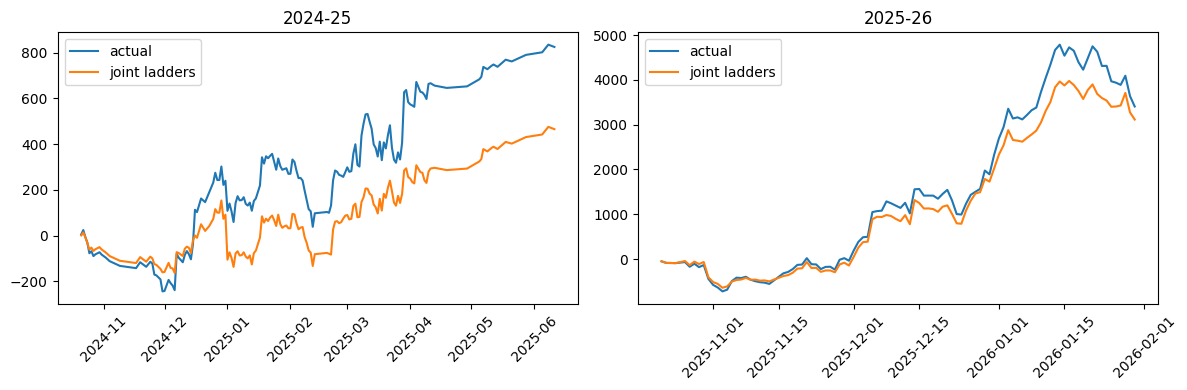

In [11]:
daily = H.groupby(['season', 'date'])[['pl_actual', 'pl_joint']].sum().reset_index()
daily['B0'] = daily.season.map(BANKROLL)

def max_drawdown(x):
    c = np.cumsum(x)
    return (np.maximum.accumulate(np.concatenate([[0], c]))[1:] - c).max()

rows = []
for season, g in daily.groupby('season'):
    B0 = g.B0.iloc[0]
    r = {'season': season, 'days': len(g)}
    for arm in ['actual', 'joint']:
        x = g['pl_' + arm].values
        # compounding replay
        B = B0
        for pl in x:
            B = B + pl * B / B0
        r['pl_' + arm] = x.sum()
        r['daily_sd_' + arm] = x.std()
        r['worst_day_' + arm] = x.min()
        r['max_dd_' + arm] = max_drawdown(x)
        r['log_growth_static_' + arm] = np.log(1 + x / B0).sum()
        r['end_bankroll_compound_' + arm] = B
    rows.append(r)
print(pd.DataFrame(rows).set_index('season').round(2).T.to_string())

fig, axes = plt.subplots(1, daily.season.nunique(), figsize=(12, 4))
for ax, (season, g) in zip(np.atleast_1d(axes), daily.groupby('season')):
    ax.plot(g.date, g.pl_actual.cumsum(), label='actual')
    ax.plot(g.date, g.pl_joint.cumsum(), label='joint ladders')
    ax.set_title(season); ax.tick_params(axis='x', rotation=45); ax.legend()
plt.tight_layout(); plt.show()

### 5d. Is the difference real? Day-level bootstrap

Resample slates (days) with replacement and recompute the season difference (joint − actual) in P&L and in log growth. Days are the unit because bets within a slate share game-level shocks.

In [12]:
rng = np.random.default_rng(7)
N_BOOT = 5000
res = []
for season, g in daily.groupby('season'):
    B0 = g.B0.iloc[0]
    dpl = (g.pl_joint - g.pl_actual).values
    dlg = (np.log(1 + g.pl_joint / B0) - np.log(1 + g.pl_actual / B0)).values
    idx = rng.integers(0, len(g), size=(N_BOOT, len(g)))
    bpl, blg = dpl[idx].sum(1), dlg[idx].sum(1)
    res.append({'season': season, 'dPL': dpl.sum(), 'dPL_2.5%': np.percentile(bpl, 2.5), 'dPL_97.5%': np.percentile(bpl, 97.5),
                'P(dPL>0)': (bpl > 0).mean(), 'dLogGrowth': dlg.sum(), 'dLG_2.5%': np.percentile(blg, 2.5),
                'dLG_97.5%': np.percentile(blg, 97.5), 'P(dLG>0)': (blg > 0).mean()})
print(pd.DataFrame(res).set_index('season').round(3).T.to_string())

season      2024-25   2025-26
dPL        -359.291  -291.128
dPL_2.5%   -901.154 -1475.156
dPL_97.5%   112.092   881.526
P(dPL>0)      0.075     0.319
dLogGrowth   -0.484     0.224
dLG_2.5%     -1.483    -0.990
dLG_97.5%     0.436     1.509
P(dLG>0)      0.156     0.621


## 6. Right-tail calibration by rung

Joint sizing and calibration are **separate fixes that compound**:
- Calibration fixes $p$. If the top rungs' probabilities were overconfident, their edges were inflated.
- Joint sizing fixes the allocation given $p$. Even with perfectly calibrated probabilities, the top rung gets trimmed for the overlap reason in section 3.
- Independent sizing puts the most excess stake on the top rungs, so overconfidence and overlap stack exactly there.

Reliability check: mean backed-out $p$ vs actual hit rate, by rung and by probability bin. Hit-rate standard errors are binomial.

By rung (overs):
                        n  book_implied  model_p  hit_rate     se  z(hit-model)
season  rung                                                                   
2024-25 1 (lowest)  165.0         0.419    0.519     0.430  0.039        -2.281
        2           164.0         0.219    0.321     0.274  0.035        -1.266
        3+           48.0         0.131    0.223     0.208  0.059        -0.249
        single      582.0         0.356    0.443     0.369  0.020        -3.574
2025-26 1 (lowest)  391.0         0.508    0.595     0.504  0.025        -3.671
        2           390.0         0.273    0.359     0.279  0.023        -3.287
        3+          139.0         0.157    0.232     0.165  0.032        -1.860
        single      366.0         0.391    0.464     0.402  0.026        -2.387

By model-probability bin (all overs, both seasons):
                n  book_implied  model_p  hit_rate     se  z(hit-model)
p_bin                                                     

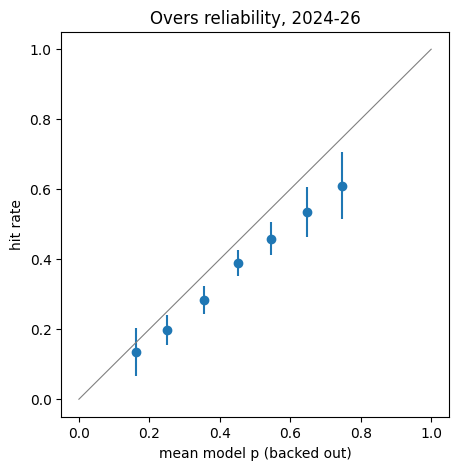

In [13]:
ov_all = H[(H.is_ladder) & (H.side == 'Over') & (H.p < 1)].copy()
ov_all['rung'] = ov_all.groupby(['date', 'name']).line.rank(method='first').astype(int).clip(upper=3).map({1: '1 (lowest)', 2: '2', 3: '3+'})
singles_over = H[(~H.is_ladder) & (H.side == 'Over') & (H.p < 1)].assign(rung='single')
cal = pd.concat([ov_all, singles_over])

def rel(g):
    n = len(g); hit = g.won.mean(); mp = g.p.mean(); imp = (1 / g.d).mean()
    return pd.Series({'n': n, 'book_implied': imp, 'model_p': mp, 'hit_rate': hit, 'se': np.sqrt(hit * (1 - hit) / n),
                      'z(hit-model)': (hit - mp) / np.sqrt(mp * (1 - mp) / n)})

print('By rung (overs):')
print(cal.groupby(['season', 'rung'])[['won', 'p', 'd']].apply(rel).round(3).to_string())

cal['p_bin'] = pd.cut(cal.p, [0, .2, .3, .4, .5, .6, .7, 1])
tab = cal.groupby('p_bin', observed=True)[['won', 'p', 'd']].apply(rel)
print('\nBy model-probability bin (all overs, both seasons):')
print(tab.round(3).to_string())

fig, ax = plt.subplots(figsize=(5, 5))
ax.errorbar(tab.model_p, tab.hit_rate, yerr=1.96 * tab.se, fmt='o')
ax.plot([0, 1], [0, 1], color='grey', lw=.8)
ax.set_xlabel('mean model p (backed out)'); ax.set_ylabel('hit rate'); ax.set_title('Overs reliability, 2024-26')
plt.show()

### 6b. How much of the claimed edge was real?

For every bet we took: claimed edge $=$ model $p$ $-$ book implied, and realized edge $=$ hit rate $-$ book implied.

When the realized edge is well below the claimed edge, that's the **winner's curse**. We only bet when the model disagrees with the book, and that disagreement is partly signal and partly model noise. Conditional on a big disagreement, the noise leans in our favor, so the model looks overconfident *on the bets we take* even if it's well calibrated over all player-games.

Kelly is proportional to edge. If only a share $r$ of the claimed edge is real, betting $\lambda$ of model-Kelly is really betting $\lambda / r$ of true Kelly.

**This depends on $B$ (unlike the joint-vs-actual comparison).** If the true bankroll was larger than assumed, the claimed edges shrink. Confirm the 2024-25 and 2025-26 bankrolls before trusting the magnitude.

In [14]:
H['book_p'] = 1 / H.d
Hc = H[H.p < 1].copy()
edge = (Hc.groupby(['season', 'side'])
          .agg(n=('won', 'size'), book_p=('book_p', 'mean'), model_p=('p', 'mean'), hit_rate=('won', 'mean'),
               stake=('stake', 'sum'), pl=('pl_actual', 'sum')))
edge['claimed_edge'] = edge.model_p - edge.book_p
edge['realized_edge'] = edge.hit_rate - edge.book_p
edge['realized/claimed'] = edge.realized_edge / edge.claimed_edge
edge['effective_kelly'] = LAMBDA / edge['realized/claimed']
edge['roi'] = edge.pl / edge.stake
print(edge.round(3).to_string())

                  n  book_p  model_p  hit_rate     stake        pl  claimed_edge  realized_edge  realized/claimed  effective_kelly    roi
season  side                                                                                                                             
2024-25 Over    959   0.332    0.424     0.356   8433.20  1005.109         0.092          0.023             0.254            0.492  0.119
        Under    15   0.492    0.571     0.667    146.75    41.217         0.079          0.175             2.212            0.057  0.281
2025-26 Over   1286   0.365    0.447     0.370  22097.37   276.343         0.082          0.005             0.059            2.121  0.013
        Under  1592   0.456    0.561     0.485  39401.24  3379.336         0.105          0.028             0.271            0.461  0.086


### 6c. Blend the model with the market

The fix the winner's curse points to is to shrink the model toward the book before sizing. Estimate the weights from history by regressing outcomes on both probabilities in logit space:

$$\text{logit}\,P(\text{win}) = \alpha + \beta_m\,\text{logit}(p_{\text{model}}) + \beta_b\,\text{logit}(p_{\text{book}})$$

- $\beta_m > 0$ means the model carries information the book doesn't.
- $\beta_m / (\beta_m + \beta_b)$ is roughly the weight the model deserves in a blend.

Standard errors are clustered by slate (date), since legs on the same night aren't independent. The book probability includes the vig, which mostly lands in $\alpha$.

In [15]:
import statsmodels.api as sm

logit = lambda x: np.log(x / (1 - x))
fits = []
for side, g in Hc.groupby('side'):
    X = sm.add_constant(pd.DataFrame({'logit_model': logit(g.p.clip(.01, .99)), 'logit_book': logit(g.book_p)}))
    fit = sm.Logit(g.won, X).fit(disp=0, cov_type='cluster', cov_kwds={'groups': pd.factorize(g.date)[0]})
    fits.append(pd.DataFrame({'side': side, 'coef': fit.params, 'se': fit.bse, 'p_value': fit.pvalues}))
    print('{}: model weight in blend ~ {:.2f}  (n={})'.format(
        side, fit.params['logit_model'] / (fit.params['logit_model'] + fit.params['logit_book']), len(g)))
print(pd.concat(fits).round(3).to_string())

Over: model weight in blend ~ 0.10  (n=2245)
Under: model weight in blend ~ 0.50  (n=1607)
              side   coef     se  p_value
const         Over -0.044  0.115    0.701
logit_model   Over  0.089  0.281    0.750
logit_book    Over  0.787  0.279    0.005
const        Under -0.103  0.138    0.455
logit_model  Under  0.560  0.293    0.056
logit_book   Under  0.553  0.295    0.061


## 7. Sensitivity to the bankroll assumption

If the true $B$ differs from what we assumed, every backed-out $p$ shifts. A $B$ that is too small inflates edges, and one that is too large shrinks them toward the book. Rerun the ladder summary at 0.5×, 1×, and 2× the assumed bankroll. If the conclusions hold across that range, the assumption doesn't drive them.

In [16]:
sens = []
for m in [0.5, 1.0, 2.0]:
    Hm = replay(legs_h, bank_mult=m)
    okm = Hm[Hm.status == 'ok']
    for season, g in okm.groupby('season'):
        sens.append({'bank_mult': m, 'season': season, 'ladder_legs_ok': len(g),
                     'excluded': (Hm[(Hm.is_ladder) & (Hm.season == season)].status != 'ok').sum(),
                     'stake_cut': 1 - g.stake_joint.sum() / g.stake.sum(),
                     'pl_actual': g.pl_actual.sum(), 'pl_joint': g.pl_joint.sum(),
                     'ev_actual': g.ev_actual.sum(), 'ev_joint': g.ev_joint.sum()})
print(pd.DataFrame(sens).round(3).to_string(index=False))

 bank_mult  season  ladder_legs_ok  excluded  stake_cut  pl_actual  pl_joint  ev_actual  ev_joint
       0.5 2024-25             376         2      0.480    743.716   384.412   2915.662  1735.573
       0.5 2025-26            1270        18      0.436   1110.374   861.926  15578.872  9692.925
       1.0 2024-25             376         2      0.480    743.716   384.424   1457.831   867.786
       1.0 2025-26            1284         4      0.434   1505.922  1214.794   8094.246  5088.949
       2.0 2024-25             376         2      0.480    743.716   384.409    728.916   433.893
       2.0 2025-26            1284         4      0.434   1505.922  1214.801   4047.123  2544.474


## Notes and limits

- **Survivorship in the replay.** We can only re-size legs we actually bet. Joint sizing could also *add* a leg we skipped (for example, a middle rung that only makes sense alongside others), and the replay can't see those.
- **Limited fills** bias backed-out $p$ toward the book's price, which understates the edge on those legs and makes joint sizing look a bit more conservative than it would be.
- **Pikkit export ends January 2026.** Re-export it to cover February–April 2026.
- **P&L is recomputed at the listed odds**, so both arms are on the same basis. Pikkit's own profit column is higher (see section 5), most likely because of profit boosts. The replay doesn't credit those.
- **Manual overrides** (stake > $\lambda B$, like a $222 bet on a $500 bankroll) can't be backed out. Those ladders keep their actual stakes in both arms.
- **Cross-player correlation** (same team or same game) is not modeled here. Each ladder is optimized on its own. That's the next layer: simulate a shared game-level factor.